In [1]:
# If you are running in Colab, TensorFlow is usually already installed.
# If needed, uncomment the next line:
# !pip install -q tensorflow

import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow version: 2.21.0


In [2]:
# Load the dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training shape:", x_train.shape)
print("Test shape:", x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Training shape: (60000, 28, 28)
Test shape: (10000, 28, 28)


In [3]:
# Normalize and reshape
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, -1)  # (60000, 28, 28, 1)
x_test = np.expand_dims(x_test, -1)    # (10000, 28, 28, 1)

print("Reshaped training shape:", x_train.shape)
print("Reshaped test shape:", x_test.shape)

Reshaped training shape: (60000, 28, 28, 1)
Reshaped test shape: (10000, 28, 28, 1)


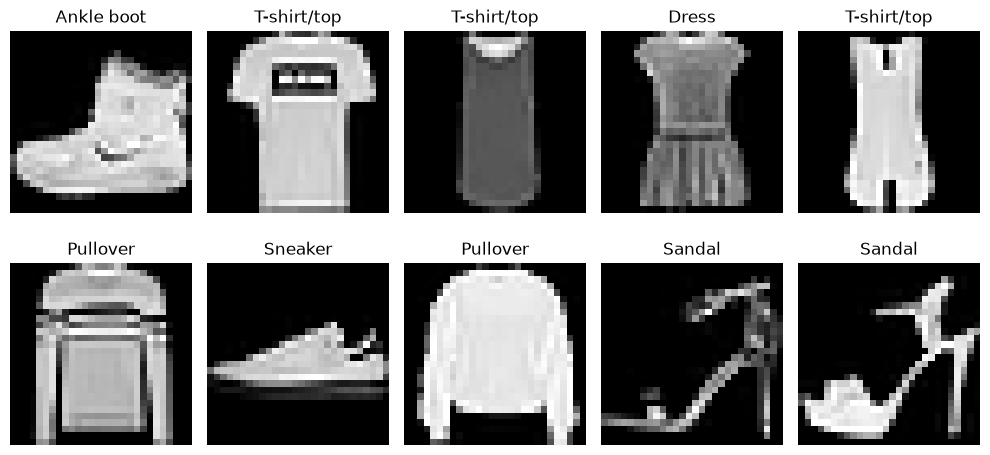

In [4]:
# Visualize a few training samples
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [5]:
def build_baseline_model():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, kernel_size=3, activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(64, kernel_size=3, activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

baseline_model = build_baseline_model()
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train the baseline model
baseline_history = baseline_model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

baseline_test_loss, baseline_test_acc = baseline_model.evaluate(x_test, y_test, verbose=0)
print(f"Baseline test accuracy: {baseline_test_acc:.4f}")

Epoch 1/5


422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7786 - loss: 0.6142

422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.7786 - loss: 0.6142 - val_accuracy: 0.8580 - val_loss: 0.3909


Epoch 2/5


422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8619 - loss: 0.3835 - val_accuracy: 0.8823 - val_loss: 0.3238


...

Epoch 4/5


422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.8891 - loss: 0.3023 - val_accuracy: 0.8968 - val_loss: 0.2879


Epoch 5/5


422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.8960 - loss: 0.2824 - val_accuracy: 0.9017 - val_loss: 0.2685


Baseline test accuracy: 0.8940


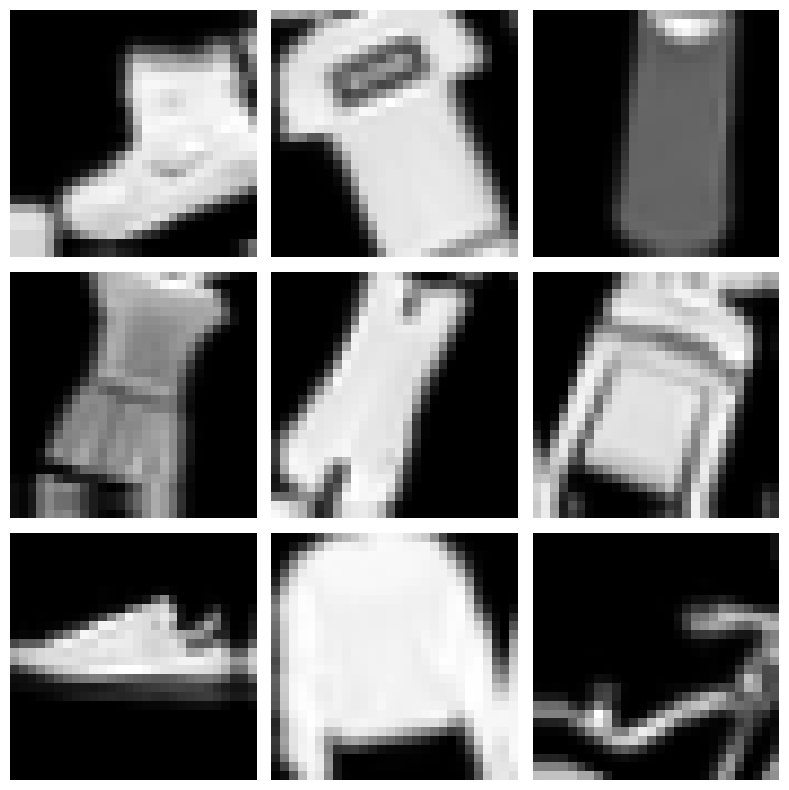

In [7]:
# Data augmentation pipeline
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(height_factor=0.08, width_factor=0.08),
], name="data_augmentation")

# Preview augmented images
sample_batch = x_train[:9]

plt.figure(figsize=(8, 8))
for i in range(9):
    augmented = data_augmentation(tf.expand_dims(sample_batch[i], 0), training=True)
    plt.subplot(3, 3, i + 1)
    plt.imshow(augmented[0].numpy().squeeze(), cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [8]:
def build_augmented_model():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        data_augmentation,
        layers.Conv2D(32, kernel_size=3, activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(64, kernel_size=3, activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

augmented_model = build_augmented_model()
augmented_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Train the augmented model
augmented_history = augmented_model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

augmented_test_loss, augmented_test_acc = augmented_model.evaluate(x_test, y_test, verbose=0)
print(f"Augmented test accuracy: {augmented_test_acc:.4f}")

Epoch 1/5


422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 28ms/step - accuracy: 0.6692 - loss: 0.8891 - val_accuracy: 0.7652 - val_loss: 0.6170


Epoch 2/5


422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - accuracy: 0.7574 - loss: 0.6452 - val_accuracy: 0.7803 - val_loss: 0.5928


Epoch 3/5


...

422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.7986 - loss: 0.5432 - val_accuracy: 0.8158 - val_loss: 0.4772


Epoch 5/5


422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8075 - loss: 0.5152

422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - accuracy: 0.8075 - loss: 0.5152 - val_accuracy: 0.8243 - val_loss: 0.4563


Augmented test accuracy: 0.8213


Accuracy difference (augmented - baseline): -0.0727


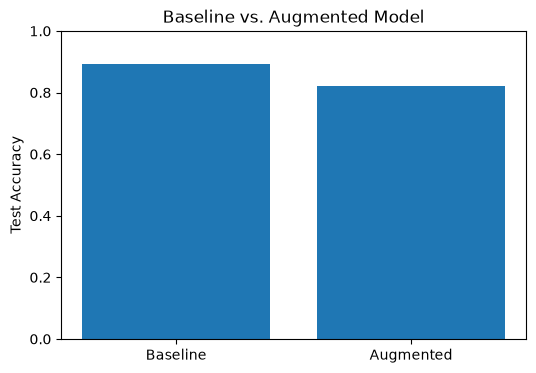

In [10]:
# Compare the two results
improvement = augmented_test_acc - baseline_test_acc
print(f"Accuracy difference (augmented - baseline): {improvement:.4f}")

plt.figure(figsize=(6, 4))
plt.bar(["Baseline", "Augmented"], [baseline_test_acc, augmented_test_acc])
plt.ylabel("Test Accuracy")
plt.title("Baseline vs. Augmented Model")
plt.ylim(0.0, 1.0)
plt.show()

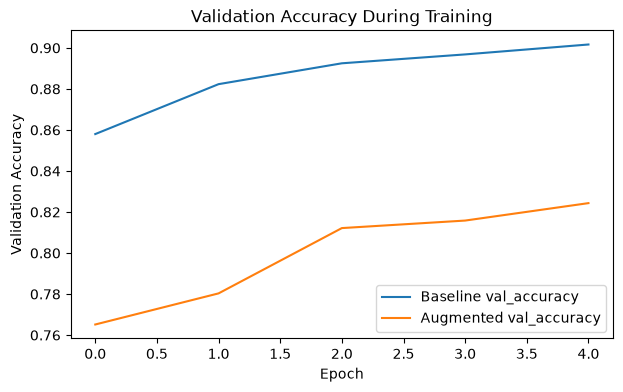

In [11]:
# Plot training histories
plt.figure(figsize=(7, 4))
plt.plot(baseline_history.history["val_accuracy"], label="Baseline val_accuracy")
plt.plot(augmented_history.history["val_accuracy"], label="Augmented val_accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy During Training")
plt.legend()
plt.show()

In [12]:
print("Reflection")
if augmented_test_acc > baseline_test_acc:
    print(f"Data augmentation improved test accuracy by {improvement:.4f}.")
elif augmented_test_acc < baseline_test_acc:
    print(f"Data augmentation reduced test accuracy by {abs(improvement):.4f}.")
else:
    print("Data augmentation produced the same test accuracy as the baseline model.")

print("Data augmentation can help generalization, but only when the transformations fit the dataset.")
print("The main challenges were longer training time and choosing realistic augmentations.")
print("This is useful when labeled image data is limited and the model must handle variation.")


Reflection
Data augmentation reduced test accuracy by 0.0727.
Data augmentation can help generalization, but only when the transformations fit the dataset.
The main challenges were longer training time and choosing realistic augmentations.
This is useful when labeled image data is limited and the model must handle variation.
